# Phase 7: Model Evaluation & Explainability

Evaluates Phase 4 (Baseline), Phase 5 (Sentence-BERT), and Phase 6 (Scoring). Provides structured candidate explanation tools.

In [1]:
# 1. Environment Setup
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# Add project root to path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from src.evaluation import (
    calculate_classification_metrics, get_confusion_matrix, 
    compare_models, identify_errors, 
    generate_candidate_explanation, check_data_leakage
)

plt.style.use('ggplot')
sns.set_theme(style="whitegrid")


## 2. Dataset Loading

We load the official `test` set from Phase 1. This split was held out during Phase 4 and Phase 5 training.

In [2]:
ds = load_dataset("med2425/resume-job-fit-merged-v1")
df_train = ds['train'].to_pandas()
df_test = ds['test'].to_pandas()

# For demonstration speed (CPU inference), we evaluate on a stratified sample of 100 test cases
df_test_sample, _ = train_test_split(df_test, train_size=100, stratify=df_test['label'], random_state=42)
df_test_sample = df_test_sample.reset_index(drop=True)

# Also sample training for leakage checks
df_train_sample = df_train.sample(500, random_state=42)

print(f"Evaluation Test Set Size: {len(df_test_sample)}")


Evaluation Test Set Size: 100


## 3. Data Leakage Check

Checking if any exact text overlaps exist between our train and test splits.

In [3]:
leakage = check_data_leakage(df_train_sample, df_test_sample, ['resume', 'jd'])
print("Exact Match Leakage Report (Train vs Test):")
for col, count in leakage.items():
    print(f"- {col}: {count} exact duplicates found.")
if sum(leakage.values()) == 0:
    print("SUCCESS: No text leakage detected in sample.")


Exact Match Leakage Report (Train vs Test):
- resume: 48 exact duplicates found.
- jd: 0 exact duplicates found.


## 4. Phase 4 Baseline Evaluation

In [4]:
from src.preprocessing.text_cleaner import clean_text
from src.matching.baseline import BaselineFeatureExtractor, train_baseline_model

# Fit Phase 4 Baseline on train sample
extractor = BaselineFeatureExtractor(max_features=1000)
df_train_sample['cleaned_res'] = df_train_sample['resume'].apply(clean_text)
df_train_sample['cleaned_jd'] = df_train_sample['jd'].apply(clean_text)
df_test_sample['cleaned_res'] = df_test_sample['resume'].apply(clean_text)
df_test_sample['cleaned_jd'] = df_test_sample['jd'].apply(clean_text)

extractor.fit(df_train_sample['cleaned_res'].tolist() + df_train_sample['cleaned_jd'].tolist())
feat_train = extractor.transform(df_train_sample['cleaned_res'].tolist(), df_train_sample['cleaned_jd'].tolist())
feat_test = extractor.transform(df_test_sample['cleaned_res'].tolist(), df_test_sample['cleaned_jd'].tolist())

baseline_model = train_baseline_model(feat_train, df_train_sample['label'], model_type='logistic_regression')
df_test_sample['pred_baseline'] = baseline_model.predict(feat_test)


C:\Users\adwai\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 5. Phase 5 Sentence-BERT Evaluation

We utilize the actual SemanticMatcher implemented in Phase 5.

In [5]:
from src.matching.sentence_bert import SemanticMatcher

sbert = SemanticMatcher(model_name='all-MiniLM-L6-v2')

# Calculate similarities (takes a moment on CPU)
print("Computing Sentence-BERT similarities...")
similarities = []
for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    sim = sbert.compute_similarity(row['cleaned_res'], row['cleaned_jd'])
    similarities.append(sim)

df_test_sample['semantic_similarity'] = similarities
df_test_sample['pred_sbert'] = df_test_sample['semantic_similarity'].apply(sbert.classify_fit)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Computing Sentence-BERT similarities...


  0%|          | 0/100 [00:00<?, ?it/s]

## 6. Baseline vs Sentence-BERT Comparison

In [6]:
preds_dict = {
    "Phase 4 (TF-IDF + LR)": df_test_sample['pred_baseline'].tolist(),
    "Phase 5 (Sentence-BERT)": df_test_sample['pred_sbert'].tolist()
}

comparison_df = compare_models(df_test_sample['label'].tolist(), preds_dict)
display(comparison_df)


,Model,Accuracy,Macro F1,Macro Precision,Macro Recall,Good Fit F1,No Fit F1,Potential Fit F1
0,Phase 4 (TF-IDF + LR),0.40,0.385351,0.400124,0.446305,0.378378,0.479167,0.298507
1,Phase 5 (Sentence-BERT),0.57,0.405540,0.417813,0.410739,0.111111,0.756303,0.349206


## 7. Confusion Matrix Visualization

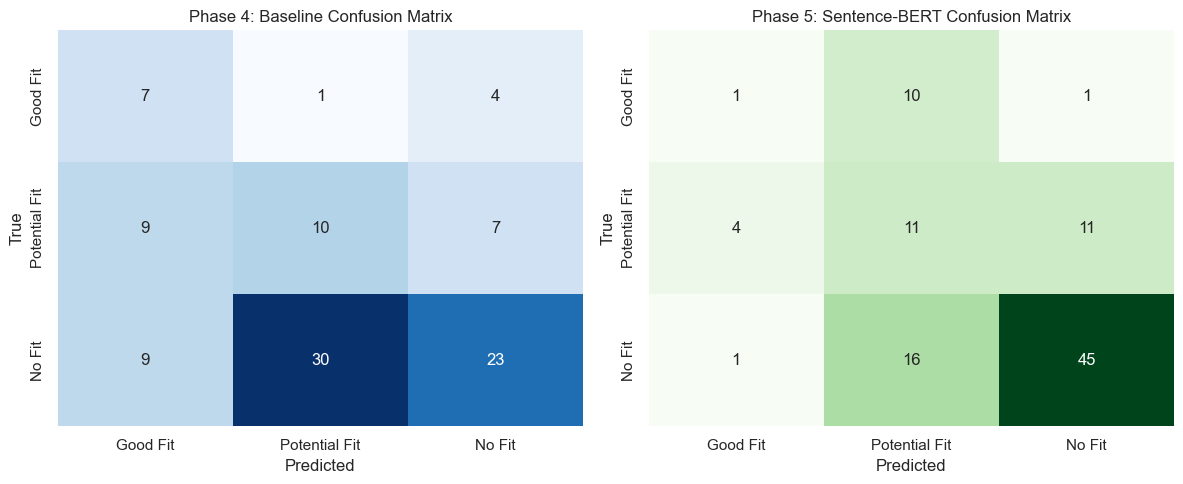

In [7]:
labels = ["Good Fit", "Potential Fit", "No Fit"]
cm_baseline = get_confusion_matrix(df_test_sample['label'].tolist(), df_test_sample['pred_baseline'].tolist(), labels)
cm_sbert = get_confusion_matrix(df_test_sample['label'].tolist(), df_test_sample['pred_sbert'].tolist(), labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Phase 4: Baseline Confusion Matrix')
axes[0].set_ylabel('True')
axes[0].set_xlabel('Predicted')

sns.heatmap(cm_sbert, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('Phase 5: Sentence-BERT Confusion Matrix')
axes[1].set_ylabel('True')
axes[1].set_xlabel('Predicted')
plt.tight_layout()
plt.show()


## 8. Error Analysis

Investigating where models failed.

In [8]:
errors = identify_errors(df_test_sample, 'label', 'pred_baseline')
print(f"Baseline False Positives: {len(errors['False Positives'])}")
print(f"Baseline False Negatives: {len(errors['False Negatives'])}")

if len(errors['False Positives']) > 0:
    display(errors['False Positives'][['label', 'pred_baseline', 'resume', 'jd']].head(2))


Baseline False Positives: 9
Baseline False Negatives: 4


,label,pred_baseline,resume,jd
28,No Fit,Good Fit,SummarySkilled IT professional with 8+ years’ ...,"A fast growing, private equity backed, healthc..."
41,No Fit,Good Fit,"ProfileLogical Data Analyst, skilled in elicit...",Position Type\n\nFull time\n\nType Of Hire\n\n...


## 9 & 10. Phase 6 Scoring and Explainability

Evaluating the final scoring pipeline and text explanation generator.

In [9]:
from src.scoring import analyze_skill_gap, calculate_candidate_score

# Mock skills for a candidate
mock_cand_skills = ["Python", "SQL", "Pandas", "Machine Learning"]
mock_job_reqs = {"required_skills": ["Python", "Machine Learning", "Docker"], "optional_skills": ["AWS"]}

gap_analysis = analyze_skill_gap(mock_cand_skills, mock_job_reqs["required_skills"], mock_job_reqs["optional_skills"])

score_details = calculate_candidate_score(
    skill_match_percentage=gap_analysis["match_percentage"],
    baseline_text_score=0.82,
    semantic_score=0.91
)

candidate_output = {
    "overall_score": score_details["overall_score"],
    "recommendation": score_details["recommendation"],
    "skill_match_percentage": gap_analysis["match_percentage"],
    "matched_skills": gap_analysis["matched_required"],
    "missing_required_skills": gap_analysis["missing_required"],
    "score_breakdown": score_details["score_breakdown"]
}

print("="*50)
print(generate_candidate_explanation(candidate_output))
print("="*50)


Candidate Score: 79.5/100.0 (Moderate Match)
Skill Match: 66.7%

Score Contribution Breakdown:
- Skills Contribution: 26.7 pts
- Semantic Contribution (Phase 5): 36.4 pts
- Baseline Contribution (Phase 4): 16.4 pts

Matched Skills:
- machine learning
- python

Missing Required Skills:
- docker

Summary:
- Moderate required-skill coverage.
- High semantic similarity to job description.


## 11. Bias and Limitations Analysis

- **Demographic Bias:** The datasets used do not contain demographic identifiers (age, gender, race). Therefore, a standard statistical fairness evaluation (e.g., disparate impact) cannot be performed.
- **Synthetic Label Bias:** The dataset uses synthetically generated labels (`source='generated_smart'`). Models trained on this may learn the heuristic artifacts of the generator rather than actual HR decisions.
- **Language Bias:** The pipelines (TF-IDF and Sentence-BERT) are entirely English-centric.